# 04b – Le LSTM avec l'âge du moteur

**Hypothèse testée :** le LSTM faisait moins bien que LightGBM au dernier cycle du test (15,74 contre 13,53) parce qu'il ne connaît pas l'âge du moteur. LightGBM avait la feature `cycle`, sa 3ᵉ plus importante ; le LSTM ne voyait que les 30 derniers cycles de capteurs.

**Expérience :** on ajoute le cycle normalisé comme 15ᵉ entrée du LSTM, on garde **tout le reste identique** (architecture, hyperparamètres, graine aléatoire), et on compare. Ne changer qu'une seule chose à la fois, c'est ce qui permet d'attribuer la différence à cette chose.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from src.data.load import PROJECT_ROOT
from src.data.windows import make_windows
from src.features.preprocess import FEATURES_FD001
from src.features.rolling import add_rolling_features, last_cycle
from src.models.lstm import LSTMRegressor, train_lstm, predict_lstm, set_seed
from src.models.metrics import rmse, nasa_score

sns.set_theme(style="whitegrid")
PROC = PROJECT_ROOT / "data" / "processed"
MODELS = PROJECT_ROOT / "models"
WINDOW = 30

## 1. Ajout du cycle normalisé

Le cycle va de 1 à 362 alors que les capteurs sont centrés-réduits (autour de 0, écart-type 1). On le normalise avec la moyenne et l'écart-type **du train uniquement**, comme les capteurs.

In [2]:
sets = {k: pd.read_csv(PROC / f"FD001_{k}.csv") for k in ["train", "calib", "val", "test"]}

mu, sigma = sets["train"]["cycle"].mean(), sets["train"]["cycle"].std()
print(f"Normalisation du cycle : moyenne {mu:.1f}, écart-type {sigma:.1f} (calculés sur le train)")
for df in sets.values():
    df["cycle_norm"] = (df["cycle"] - mu) / sigma

FEATS_AGE = FEATURES_FD001 + ["cycle_norm"]
W_base = {k: make_windows(v, FEATURES_FD001, window=WINDOW) for k, v in sets.items()}
W_age = {k: make_windows(v, FEATS_AGE, window=WINDOW) for k, v in sets.items()}
print("Avant :", W_base["train"][0].shape, "| Après :", W_age["train"][0].shape)

Normalisation du cycle : moyenne 108.9, écart-type 69.5 (calculés sur le train)
Avant : (14407, 30, 14) | Après : (14407, 30, 15)


## 2. Entraînement avec exactement les mêmes réglages qu'au notebook 04

In [3]:
set_seed(42)
model_age = LSTMRegressor(n_features=len(FEATS_AGE), hidden=64, num_layers=2, dropout=0.2)
Xtr, ytr, _ = W_age["train"]
Xva, yva, _ = W_age["val"]
model_age, hist_age = train_lstm(model_age, Xtr, ytr, Xva, yva, epochs=100, batch_size=256, lr=1e-3, patience=10)

époque   1 | RMSE train  53.25 | RMSE val  19.12 |     3s
époque   5 | RMSE train  17.92 | RMSE val  13.80 |    13s
époque  10 | RMSE train  15.68 | RMSE val  13.85 |    26s
époque  15 | RMSE train  14.51 | RMSE val  13.14 |    39s
époque  20 | RMSE train  13.52 | RMSE val  13.00 |    51s
époque  25 | RMSE train  12.28 | RMSE val  12.74 |    64s
Arrêt anticipé à l'époque 28 (meilleure val RMSE = 11.86)


## 3. Rechargement des modèles précédents

In [4]:
ck = torch.load(MODELS / "lstm_fd001.pt", weights_only=False)
model_base = LSTMRegressor(n_features=len(ck["features"]), hidden=ck["hidden"], num_layers=ck["num_layers"], dropout=ck["dropout"])
model_base.load_state_dict(ck["state_dict"])

lgb_bundle = joblib.load(MODELS / "lgbm_fd001.joblib")
lgbm, LGB_FEATS = lgb_bundle["model"], lgb_bundle["features"]

preds = {}
for k in ["val", "test"]:
    X, y, meta = W_base[k]
    df = meta.copy()
    df["RUL"] = y
    df["LSTM"] = predict_lstm(model_base, X)
    df["LSTM + âge"] = predict_lstm(model_age, W_age[k][0])
    feats = add_rolling_features(sets[k], FEATURES_FD001, windows=(5, 10, 20))
    feats["LightGBM"] = np.clip(lgbm.predict(feats[LGB_FEATS]), 0, None)
    df = df.merge(feats[["unit", "cycle", "LightGBM"]], on=["unit", "cycle"])
    df["Moyenne LGBM + LSTM âge"] = (df["LightGBM"] + df["LSTM + âge"]) / 2
    preds[k] = df

## 4. Résultat de l'expérience

In [5]:
MODELES = ["LightGBM", "LSTM", "LSTM + âge", "Moyenne LGBM + LSTM âge"]

def tableau(preds):
    rows = {}
    for m in MODELES:
        v, t = preds["val"], preds["test"]
        tl = last_cycle(t)
        rows[m] = {
            "RMSE val (toutes lignes)": rmse(v.RUL, v[m]),
            "RMSE test (toutes lignes)": rmse(t.RUL, t[m]),
            "RMSE test (dernier cycle)": rmse(tl.RUL, tl[m]),
            "Score NASA test (dernier cycle)": nasa_score(tl.RUL, tl[m]),
        }
    return pd.DataFrame(rows).round(2)

tableau(preds)

,LightGBM,LSTM,LSTM + âge,Moyenne LGBM + LSTM âge
RMSE val (toutes lignes),13.83,14.02,11.86,12.03
RMSE test (toutes lignes),13.86,14.45,13.52,12.77
RMSE test (dernier cycle),13.53,15.74,16.36,13.87
Score NASA test (dernier cycle),308.23,498.75,573.91,330.78


## 5. Où le gain se fait-il ?

Si l'hypothèse est juste, le gain doit être le plus fort sur les moteurs de test **observés peu de cycles** : sans l'âge, le LSTM ne pouvait pas savoir qu'ils étaient jeunes.

In [6]:
tl = last_cycle(preds["test"]).copy()
hist_len = preds["test"].groupby("unit").cycle.max()
tl["cycles_observés"] = tl.unit.map(hist_len)
tl["historique"] = pd.cut(tl.cycles_observés, bins=[0, 80, 140, 400], labels=["court (≤80)", "moyen (81-140)", "long (>140)"])

res = tl.groupby("historique", observed=True).apply(
    lambda d: pd.Series({m: rmse(d.RUL, d[m]) for m in ["LightGBM", "LSTM", "LSTM + âge"]} | {"n moteurs": len(d)}),
    include_groups=False)
print("RMSE au dernier cycle du test, selon la longueur de l'historique observé :")
res.round(2)

RMSE au dernier cycle du test, selon la longueur de l'historique observé :


,LightGBM,LSTM,LSTM + âge,n moteurs
historique,,,,
court (≤80),14.18,16.93,16.19,23.0
moyen (81-140),13.72,15.98,18.13,32.0
long (>140),13.04,14.91,15.07,45.0


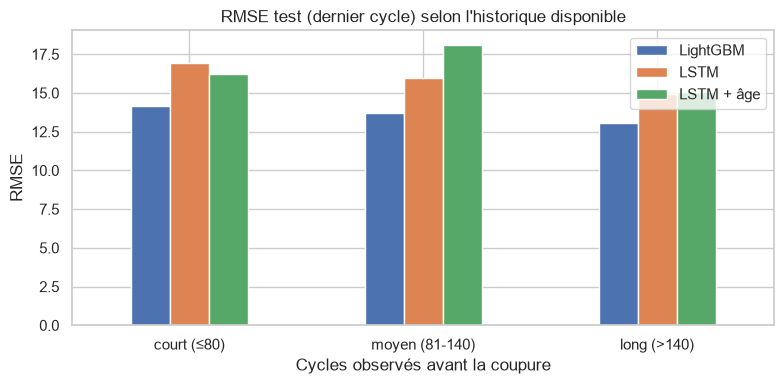

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
res.drop(columns="n moteurs").plot.bar(ax=ax, rot=0)
ax.set(title="RMSE test (dernier cycle) selon l'historique disponible", xlabel="Cycles observés avant la coupure", ylabel="RMSE")
plt.tight_layout()
plt.show()

## 6. Moteur par moteur (validation)

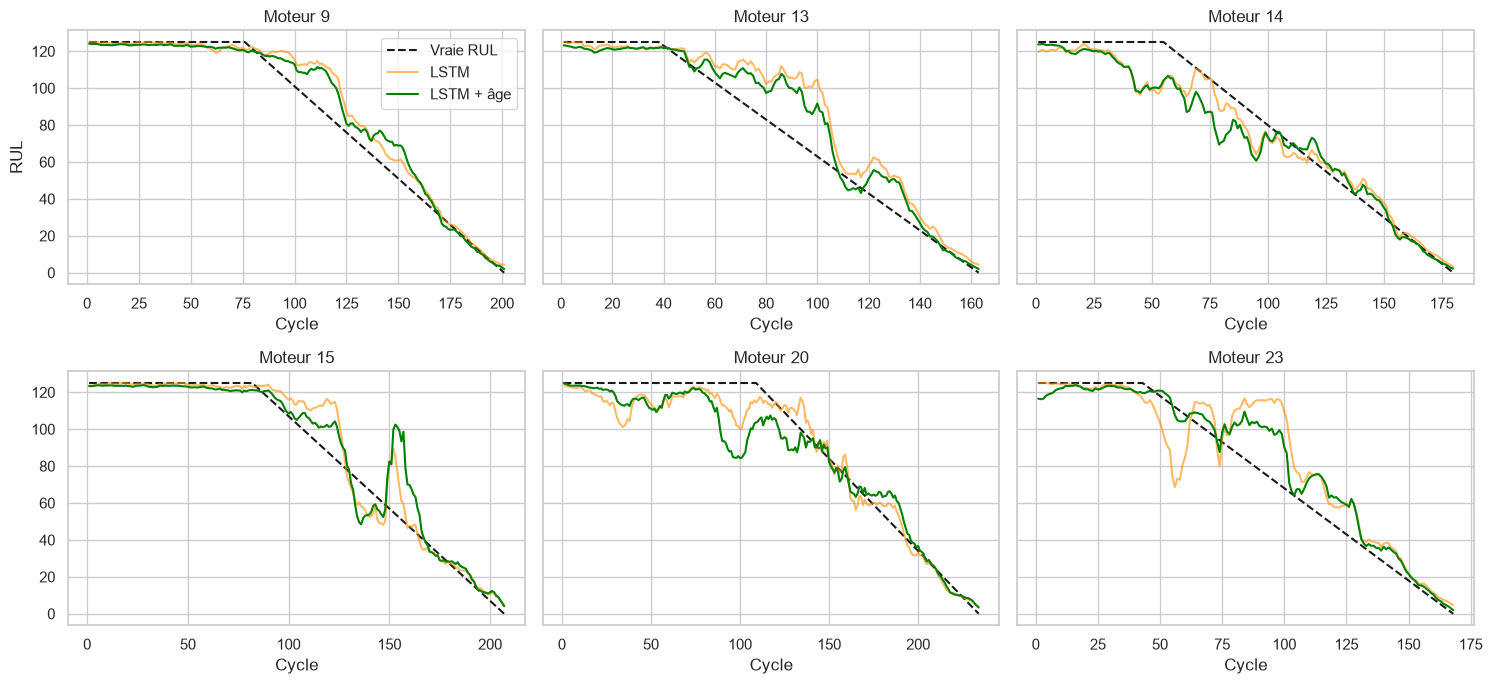

In [8]:
v = preds["val"]
units = v.unit.unique()[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, u in zip(axes.flat, units):
    d = v[v.unit == u]
    ax.plot(d.cycle, d.RUL, "k--", label="Vraie RUL")
    ax.plot(d.cycle, d["LSTM"], color="darkorange", alpha=0.6, label="LSTM")
    ax.plot(d.cycle, d["LSTM + âge"], color="green", label="LSTM + âge")
    ax.set(title=f"Moteur {u}", xlabel="Cycle")
axes[0, 0].set_ylabel("RUL")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 7. (Optionnel) Robustesse : le résultat dépend-il de la graine aléatoire ?

Un réseau de neurones donne des résultats différents selon son initialisation. Pour être sûr que l'écart n'est pas dû au hasard, on entraîne chaque version avec 3 graines. Compter environ 10 à 15 minutes : mettre `RUN_SEEDS = True` pour lancer.

In [11]:
RUN_SEEDS = True

if RUN_SEEDS:
    out = []
    for seed in [0, 1, 2]:
        for name, W, feats in [("LSTM", W_base, FEATURES_FD001), ("LSTM + âge", W_age, FEATS_AGE)]:
            set_seed(seed)
            m = LSTMRegressor(n_features=len(feats))
            m, _ = train_lstm(m, W["train"][0], W["train"][1], W["val"][0], W["val"][1], verbose=False)
            Xt, yt, mt = W["test"]
            d = mt.assign(RUL=yt, pred=predict_lstm(m, Xt))
            d = last_cycle(d)
            out.append({"modèle": name, "graine": seed, "RMSE test (dernier cycle)": rmse(d.RUL, d.pred)})
            print(out[-1])
    seeds = pd.DataFrame(out)
    print(seeds.groupby("modèle")["RMSE test (dernier cycle)"].agg(["mean", "std", "min", "max"]).round(2))

{'modèle': 'LSTM', 'graine': 0, 'RMSE test (dernier cycle)': 15.939345359802246}
{'modèle': 'LSTM + âge', 'graine': 0, 'RMSE test (dernier cycle)': 16.037389755249023}
{'modèle': 'LSTM', 'graine': 1, 'RMSE test (dernier cycle)': 15.470280647277832}
{'modèle': 'LSTM + âge', 'graine': 1, 'RMSE test (dernier cycle)': 16.373645782470703}
{'modèle': 'LSTM', 'graine': 2, 'RMSE test (dernier cycle)': 15.553473472595215}
{'modèle': 'LSTM + âge', 'graine': 2, 'RMSE test (dernier cycle)': 16.183940887451172}
             mean   std    min    max
modèle                               
LSTM        15.65  0.25  15.47  15.94
LSTM + âge  16.20  0.17  16.04  16.37


## 8. Sauvegarde

In [10]:
torch.save({"state_dict": model_age.state_dict(), "window": WINDOW, "features": FEATS_AGE,
            "cycle_mu": mu, "cycle_sigma": sigma, "hidden": 64, "num_layers": 2, "dropout": 0.2},
           MODELS / "lstm_age_fd001.pt")
print("Modèle sauvegardé")

Modèle sauvegardé


## 9. Conclusion

- **Expérience** : ajout du cycle normalisé comme 15ᵉ entrée du LSTM, tout le reste identique.
- **Toutes lignes** : amélioration nette (test 14,45 → 13,52, meilleur que LightGBM). La fausse alerte du moteur 23 disparaît.
- **Dernier cycle du test** : légère dégradation, systématique sur 3 graines (15,65 ± 0,25 → 16,20 ± 0,17 ; les fourchettes ne se chevauchent pas). L'hypothèse ne se vérifie pas pour cette mesure, et le gain attendu sur les historiques courts est faible.
- **Explication possible** : avec l'âge, le LSTM s'appuie sur une durée de vie « moyenne » et sous-estime la RUL des moteurs qui s'en écartent.
- **LightGBM reste meilleur au dernier cycle** : l'écart (~2 cycles) est près de 10 fois plus grand que la variabilité due à l'initialisation (~0,2).
- **Meilleur modèle toutes lignes** : moyenne LightGBM + LSTM avec âge (12,77 sur le test).
- **Décision** : LightGBM est retenu pour la conformal prediction. On arrête d'ajuster les modèles pour ne pas sur-optimiser sur le jeu de test.